# 液滴半径与截面：`drop.ipynb`

复用已有真实数据，运行全部单元即可重画。**绘图代码均在本 notebook 内**，输入数据放在本地相邻 `data/`，尚未授权公开；公开仓库只提供其说明。GitHub可查看预执行输出，重运行须先放入本地数据；不访问集群、不重新模拟。

- 半径图：无涨落 + OU–SE/白噪声各4条轨迹的均值与样本SD；横轴log，纵轴自然坐标，保留 $t^{1/10}$、$t^{1/6}$ 参考。
- 三条轮廓：**OU–SE单轨迹原始中心截线**、**OU–SE先环向后4seed平均**、**无涨落单场环向轮廓**；另有左侧边缘放大。
- 单独保留三方法穿白噪声触底格的同位置原始截线、log纵轴放大和二维原网格放大。这组诊断不与上述中心轮廓混淆。

所有图均标记噪声幅度：无涨落 $\varphi=0$，OU–SE/白噪声 $\varphi=0.001$。无涨落是旧版参考（$\Delta t=0.03125$，只到 $t=1000$），噪声为 $\Delta t=0.003125$；不外推，不称同版本同步长对照。

## 1. 参数与环境
依赖 NumPy、Pandas、SciPy、Matplotlib 和 LaTeX（含 `latex`、`dvipng`、`dvips`）。若系统找不到TeX，在 `LATEX_BIN` 填其可执行文件目录；不降级为数学字体模拟。

In [1]:
from pathlib import Path
import os, shutil, json, hashlib, struct
import numpy as np
import pandas as pd
from scipy import ndimage
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from IPython.display import display

get_ipython().run_line_magic('matplotlib', 'inline')
DATA_DIR = Path('data')
OUTPUT_DIR = Path('figures')
LATEX_BIN = None             # 如系统PATH已有TeX，保持None
OU_RAW_CASE = 'ou_seed102701'
WHITE_CASE = 'white_seed102801'
SECTION_TIME = 1000
SECTION_XLIM = (-12, 12)
SECTION_ZOOM = (-6.5, -3.5)  # 三条中心轮廓的同一左侧边缘窗口
CONTACT_HALF_WIDTH = 1.5
FIT_WINDOW = (1000, 2000)   # 仅OU/白噪声；无涨落没有此窗口的数据

if LATEX_BIN:
    os.environ['PATH'] = str(LATEX_BIN) + os.pathsep + os.environ.get('PATH', '')
missing = [s for s in ('latex', 'dvipng', 'dvips') if shutil.which(s) is None]
if missing:
    raise RuntimeError('请安装/配置TeX工具: ' + ', '.join(missing))
OUTPUT_DIR.mkdir(exist_ok=True)
mpl.rcParams.update({
    'text.usetex': True, 'text.latex.preamble': r'\usepackage{amsmath}',
    'font.family': 'serif', 'font.size': 20, 'figure.figsize': (8, 6),
    'figure.dpi': 150, 'axes.labelsize': 20, 'axes.titlesize': 20,
    'xtick.labelsize': 20, 'ytick.labelsize': 20, 'legend.fontsize': 20,
    'figure.titlesize': 20, 'legend.frameon': False, 'axes.grid': False, 'axes.spines.top': False,
    'axes.spines.right': False, 'xtick.direction': 'out', 'ytick.direction': 'out',
    'axes.linewidth': 1.2, 'pdf.fonttype': 42, 'savefig.bbox': None,
})
BLACK, RED, BLUE = '#000000', '#D62728', '#1F77B4'
def canvas():
    fig, ax = plt.subplots(figsize=(8, 6))
    fig.subplots_adjust(left=.17, right=.97, bottom=.17, top=.65)
    return fig, ax
def finish(fig, name):
    for ax in fig.axes:
        ax.grid(False, which='both')
    fig.savefig(OUTPUT_DIR / (name + '.pdf'))
    fig.savefig(OUTPUT_DIR / (name + '.png'), dpi=600)
    display(fig)
    plt.close(fig)

## 2. 数据、校验与来源
原场NPZ保存9个未平滑的256²高度数组（4 OU、4白、1无涨落），可重建原二进制SHA。半径CSV来自完整保存时序：噪声1616个原场、无涨落1001个原场。更换数据包时同步更换元数据与校验清单；不能只改时间标题。

In [2]:
manifest = json.loads((DATA_DIR / 'manifest.sha256.json').read_text())
for name, item in manifest.items():
    assert hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() == item['sha256'], name
meta = json.loads((DATA_DIR / 'metadata.json').read_text())
assert SECTION_TIME == meta['native_time'], '本数据包仅含t1000截面原场；换时间须换原场'
native = dict(np.load(DATA_DIR / 'native_fields_t1000.npz', allow_pickle=False))
for case, h in native.items():
    assert h.shape == (meta['N'], meta['N']) and np.isfinite(h).all()
    raw_bytes = struct.pack('<i', len(h)) + np.asarray(h, dtype='<f8').tobytes()
    assert hashlib.sha256(raw_bytes).hexdigest() == meta['sources'][case]['native_sha256']
noise = pd.read_csv(DATA_DIR / 'radii_noise.csv', float_precision='round_trip')
det_radii = pd.read_csv(DATA_DIR / 'radii_deterministic.csv', float_precision='round_trip')
assert len(noise) == 1616 and noise['case'].nunique() == 8
assert det_radii.time.max() == 1000 and len(det_radii) == 1001
L, HP, DX = meta['L'], meta['hp'], meta['dx']
PHI = meta['noise_phi']
OU_CASES = sorted(k for k, s in meta['sources'].items() if s['method'] == 'OU-SE')
WHITE_CASES = sorted(k for k, s in meta['sources'].items() if s['method'] == 'White')
assert len(OU_CASES) == len(WHITE_CASES) == 4
display(pd.DataFrame([
    {'method': 'Deterministic', 'varphi': 0, 'dt': meta['deterministic_dt'], 'trajectories': 1, 't_end': 1000},
    {'method': 'OU-SE', 'varphi': PHI, 'dt': meta['noise_dt'], 'trajectories': 4, 't_end': 2000},
    {'method': 'White', 'varphi': PHI, 'dt': meta['noise_dt'], 'trajectories': 4, 't_end': 2000},
]))

,method,varphi,dt,trajectories,t_end
0,Deterministic,0.000,0.031250,1,1000
1,OU-SE,0.001,0.003125,4,2000
2,White,0.001,0.003125,4,2000


## 3. 环向轮廓与局部二阶矩
沿用原分析算法：以主液滴核的超额质量确定中心，再作720个角向样本的环均。半径定义
$$R_2^2=\frac{\int_0^{r_c}(\bar h-h_p)r^3\,dr}{\int_0^{r_c}(\bar h-h_p)r\,dr},$$
其中 $r_c$ 为峰后环向超额厚度首次降至峰值1%的位置。这是局部二阶矩尺度，**不是接触线半径，也不是全域正超额二阶矩**。

下面复用原 `observable` 核心函数，既计算图中的平均轮廓，也重算9个t1000原场半径核对CSV。角向插值只用于环均；原始截线始终直接取原生网格。

In [3]:
integrate_trapezoid = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz

def crossing(values,r,threshold,start):
    below=np.flatnonzero(values[start:]<=threshold)
    if not len(below):return float('nan')
    k=start+int(below[0])
    if k==0:return float(r[0])
    a,b=values[k-1:k+1]
    return float(r[k-1]+(r[k]-r[k-1])*(a-threshold)/(a-b)) if a!=b else float(r[k])

def observable(h,L,hp=.01):
    if not np.all(np.isfinite(h)):raise ValueError('nonfinite field')
    n=len(h);dx=L/n;ex=h-hp
    wet=h>hp+.05*float(np.max(ex))
    labels,count=ndimage.label(wet)
    if not count:raise ValueError('no droplet core')
    masses=ndimage.sum(np.maximum(ex,0),labels,index=np.arange(1,count+1))
    main=labels==(int(np.argmax(masses))+1)
    core=ndimage.binary_fill_holes(ndimage.binary_dilation(main,iterations=1))
    weights=np.maximum(ex,0)*core
    yy,xx=np.indices(h.shape);xx=(xx+.5)*dx;yy=(yy+.5)*dx
    cx=float(np.sum(weights*xx)/np.sum(weights));cy=float(np.sum(weights*yy)/np.sum(weights))
    rlimit=min(cx,L-cx,cy,L-cy)-2*dx
    if rlimit<=0:raise ValueError('core touches box boundary')
    r=np.arange(0,rlimit,dx/4)
    theta=(np.arange(720)+.5)*2*np.pi/720
    sx=cx+np.cos(theta)[:,None]*r
    sy=cy+np.sin(theta)[:,None]*r
    rays=ndimage.map_coordinates(h,[(sy/dx-.5).ravel(),(sx/dx-.5).ravel()],
                                order=1,mode='wrap',prefilter=False).reshape(720,-1)
    mean=rays.mean(axis=0); spread=rays.std(axis=0,ddof=1); g=mean-hp
    peak=int(np.argmax(g));amp=float(g[peak])
    result=dict(cx=cx,cy=cy,hpeak_annular=amp+hp,total_volume=float(h.sum()*dx*dx),
                total_excess_signed=float(ex.sum()*dx*dx),components=count,
                core_touches_boundary=bool(np.any(core[[0,-1],:]) or np.any(core[:,[0,-1]])),
                whole_positive_ell=float(np.sqrt(np.sum(np.maximum(ex,0)*((xx-cx)**2+(yy-cy)**2))/(2*np.maximum(ex,0).sum()))))
    for q in (.005,.01,.02,.05,.1):
        cut=crossing(g,r,q*amp,peak)
        tag=f'{q:g}'
        result[f'R_annular_q{tag}']=cut
        if np.isfinite(cut):
            k=np.searchsorted(r,cut)
            rr=np.append(r[:k],cut);gg=np.append(g[:k],q*amp)
            m=float(2*np.pi*integrate_trapezoid(gg*rr,rr))
            second=float(2*np.pi*integrate_trapezoid(gg*rr**3,rr))
            result[f'ell_annular_q{tag}']=float(np.sqrt(second/(2*m))) if m>0 else float('nan')
            result[f'mass_fraction_q{tag}']=m/result['total_excess_signed']
    result['R_annular_h003']=crossing(g,r,.02,peak)
    radial=[crossing(ray-hp,r,.02,peak) for ray in rays]
    good=np.asarray(radial)[np.isfinite(radial)]
    result['R_directional_h003_mean']=float(np.mean(good)) if len(good) else float('nan')
    result['R_directional_h003_SD']=float(np.std(good,ddof=1)) if len(good)>1 else float('nan')
    result['directional_valid_fraction']=float(len(good)/720)
    return result,np.column_stack((r,mean,spread))

In [4]:
observations, profiles = {}, {}
for case, h in native.items():
    obs, profile = observable(h, L, HP)
    observations[case], profiles[case] = obs, profile
    r2 = np.sqrt(2) * obs['ell_annular_q0.01']
    assert abs(r2 - meta['sources'][case]['R2_t1000']) < 1e-11
U, W, H = native[OU_RAW_CASE], native[WHITE_CASE], native['deterministic']
xy = (np.arange(meta['N']) + .5) * DX
cx, cy = observations[OU_RAW_CASE]['cx'], observations[OU_RAW_CASE]['cy']
raw_row = int(np.argmin(abs(xy - cy)))
raw_x, raw_h = xy - cx, U[raw_row]
radial_r = np.arange(0, 12.001, DX / 4)
ou_profiles = np.stack([np.interp(radial_r, profiles[k][:, 0], profiles[k][:, 1]) for k in OU_CASES])
ou_mean, ou_sd = ou_profiles.mean(axis=0), ou_profiles.std(axis=0, ddof=1)
det_profile = np.interp(radial_r, profiles['deterministic'][:, 0], profiles['deterministic'][:, 1])
def mirror(r, h):
    return np.r_[-r[:0:-1], r], np.r_[h[:0:-1], h]
mean_x, mean_h = mirror(radial_r, ou_mean)
_, mean_sd = mirror(radial_r, ou_sd)
det_x, det_h = mirror(radial_r, det_profile)
print(f'原始OU截线: {OU_RAW_CASE}, y={xy[raw_row]:.3f}; 核心中心cy={cy:.6f}')
print('OU平均: 4条独立轨迹各自环向平均后再取均值；阴影为seed样本SD。')

原始OU截线: ou_seed102701, y=31.875; 核心中心cy=31.978654
OU平均: 4条独立轨迹各自环向平均后再取均值；阴影为seed样本SD。


## 4. 半径图
细线为单条噪声轨迹，粗线为4条均值，阴影为样本SD。指数仅拟合预设1000–2000窗口，不拟合不存在的无涨落后段。黑色参考幂率曲线只作垂直平移，不能作为收敛或渐近尺度率证明。

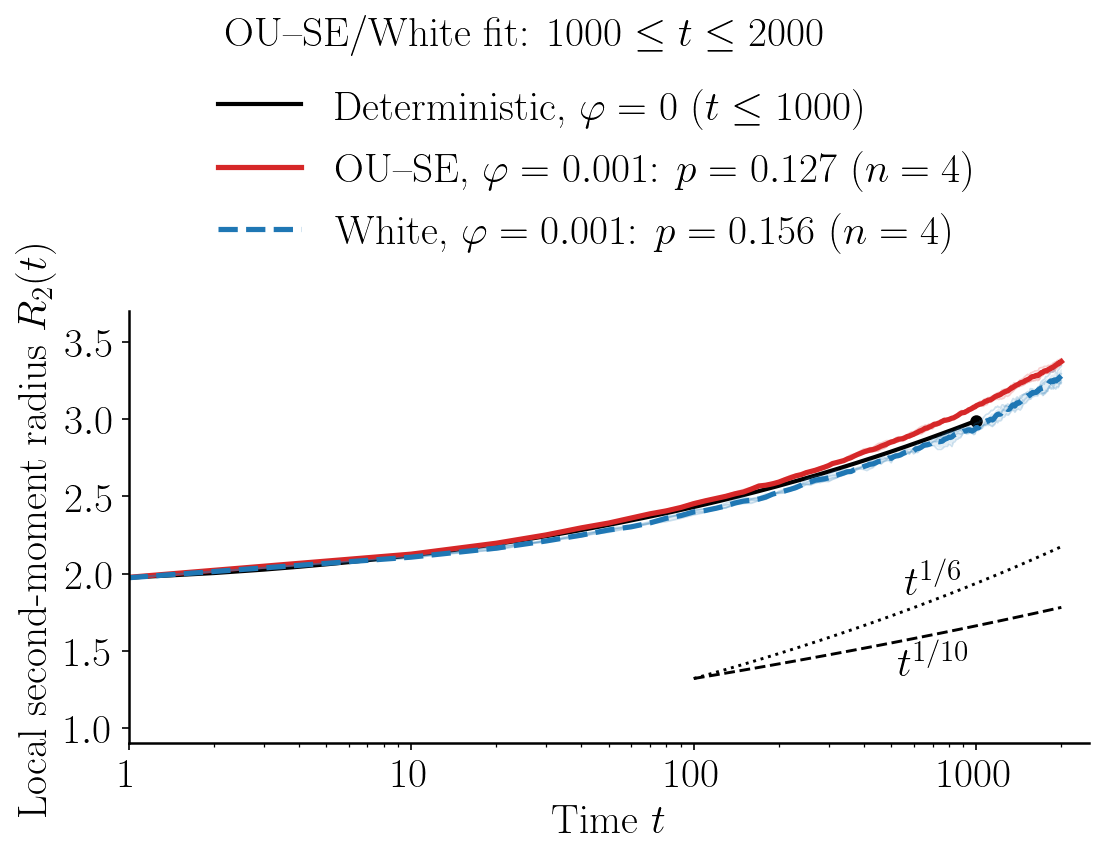

,method,start,end,p,n_seeds
0,OU-SE,1000,2000,0.127305,4
1,White,1000,2000,0.155857,4


In [5]:
fig, ax = canvas()
valid_det = det_radii[det_radii.time > 0]
ax.plot(valid_det.time, valid_det.R2, color=BLACK, lw=2,
        label=r'Deterministic, $\varphi=0$ ($t\leq1000$)')
ax.plot(valid_det.time.iloc[-1], valid_det.R2.iloc[-1], 'o', color=BLACK, ms=5)
radius_groups, fit_rows = {}, []
for mode, method, color, ls in [(2, 'OU-SE', RED, '-'), (0, 'White', BLUE, '--')]:
    z = noise[noise['mode'] == mode].pivot(index='t', columns='case', values='R2').sort_index()
    z = z[z.index > 0]
    assert z.shape[1] == 4 and z.notna().all().all()
    t, curves = z.index.to_numpy(), z.to_numpy().T
    mean, sd = curves.mean(axis=0), curves.std(axis=0, ddof=1)
    radius_groups[method] = (t, mean)
    for curve in curves:
        ax.plot(t, curve, color=color, alpha=.22, lw=.8)
    ax.fill_between(t, mean-sd, mean+sd, color=color, alpha=.12, lw=0)
    mask = (t >= FIT_WINDOW[0]) & (t <= FIT_WINDOW[1])
    exponent = float(np.polyfit(np.log(t[mask]), np.log(mean[mask]), 1)[0])
    if FIT_WINDOW == (1000, 2000):
        assert abs(exponent - meta['expected_late_exponents'][method]) < 1e-11
    fit_rows.append({'method': method, 'start': FIT_WINDOW[0], 'end': FIT_WINDOW[1], 'p': exponent, 'n_seeds': 4})
    label = ('OU--SE' if mode == 2 else 'White') + rf', $\varphi={PHI:g}$: $p={exponent:.3f}$ ($n=4$)'
    ax.plot(t, mean, color=color, ls=ls, lw=2.5, label=label)
guide_t = np.geomspace(100, 2000, 80)
anchor = .55 * min(np.interp(100, t, mean) for t, mean in radius_groups.values())
for p, ls, label in [(1/10, '--', r'$t^{1/10}$'), (1/6, ':', r'$t^{1/6}$')]:
    ax.plot(guide_t, anchor*(guide_t/100)**p, color=BLACK, ls=ls, lw=1.4)
    ax.text(700, anchor*7**p*(.88 if p == .1 else 1.06), label, ha='center', va='center')
ax.set(xscale='log', xlim=(1, 2500), ylim=(.9, 3.7), xlabel=r'Time $t$', ylabel=r'Local second-moment radius $R_2(t)$')
ax.set_xticks([1, 10, 100, 1000]); ax.set_xticklabels(['1', '10', '100', '1000'])
ax.set_yticks([1, 1.5, 2, 2.5, 3, 3.5])
fig.suptitle(rf'OU--SE/White fit: ${FIT_WINDOW[0]}\leq t\leq{FIT_WINDOW[1]}$', y=.98)
fig.legend(loc='upper center', bbox_to_anchor=(.56, .94))
finish(fig, '01_radius_vs_time')
display(pd.DataFrame(fit_rows))

## 5. 三条轮廓：单轨迹原始、OU平均、无涨落
原始OU取最靠近其核心中心的原生网格行，横坐标为$x-c_x$。OU平均和无涨落取关于各自中心的环向轮廓并镜像。原始行与理想中心可相差至半个网格，实际行位置已在上方打印；不把非中心触底截线混入此图。

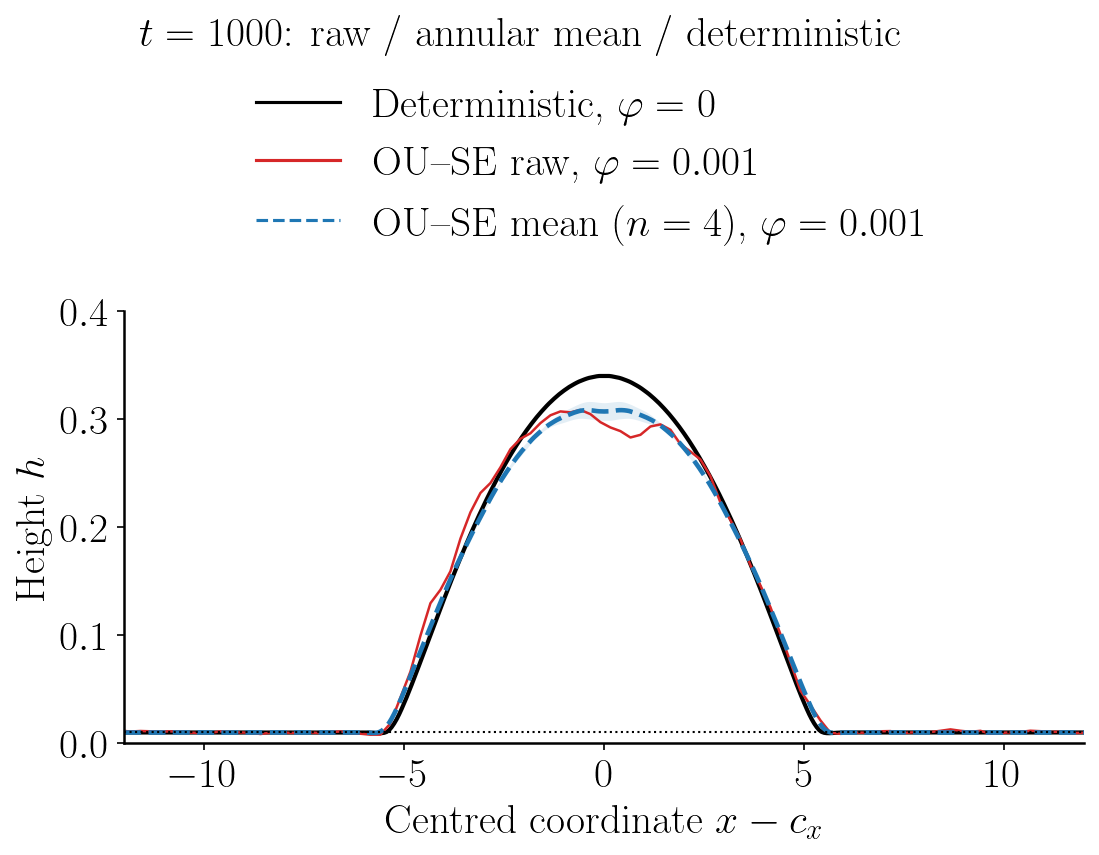

In [6]:
profile_handles = [
    Line2D([], [], color=BLACK, label=r'Deterministic, $\varphi=0$'),
    Line2D([], [], color=RED, label=rf'OU--SE raw, $\varphi={PHI:g}$'),
    Line2D([], [], color=BLUE, ls='--', label=rf'OU--SE mean ($n=4$), $\varphi={PHI:g}$'),
]
def draw_profiles(ax, markers=False):
    ax.plot(det_x, det_h, color=BLACK, lw=2)
    ax.plot(raw_x, raw_h, color=RED, lw=1.2, marker='o' if markers else None, mfc='white', ms=5)
    ax.fill_between(mean_x, mean_h-mean_sd, mean_h+mean_sd, color=BLUE, alpha=.12, lw=0)
    ax.plot(mean_x, mean_h, color=BLUE, ls='--', lw=2.2)
    ax.axhline(HP, color=BLACK, ls=':', lw=1)
fig, ax = canvas()
draw_profiles(ax)
ax.set(xlim=SECTION_XLIM, ylim=(0, .4), xlabel=r'Centred coordinate $x-c_x$', ylabel=r'Height $h$')
fig.suptitle(rf'$t={SECTION_TIME}$: raw / annular mean / deterministic', y=.98)
fig.legend(handles=profile_handles, loc='upper center', bbox_to_anchor=(.56, .94))
finish(fig, '02_ou_raw_mean_det_section')

### 左侧边缘放大
仍是上图的三条曲线；符号标出单条原始OU截线的原生网格点。蓝色阴影为4条独立seed的环均轮廓SD。

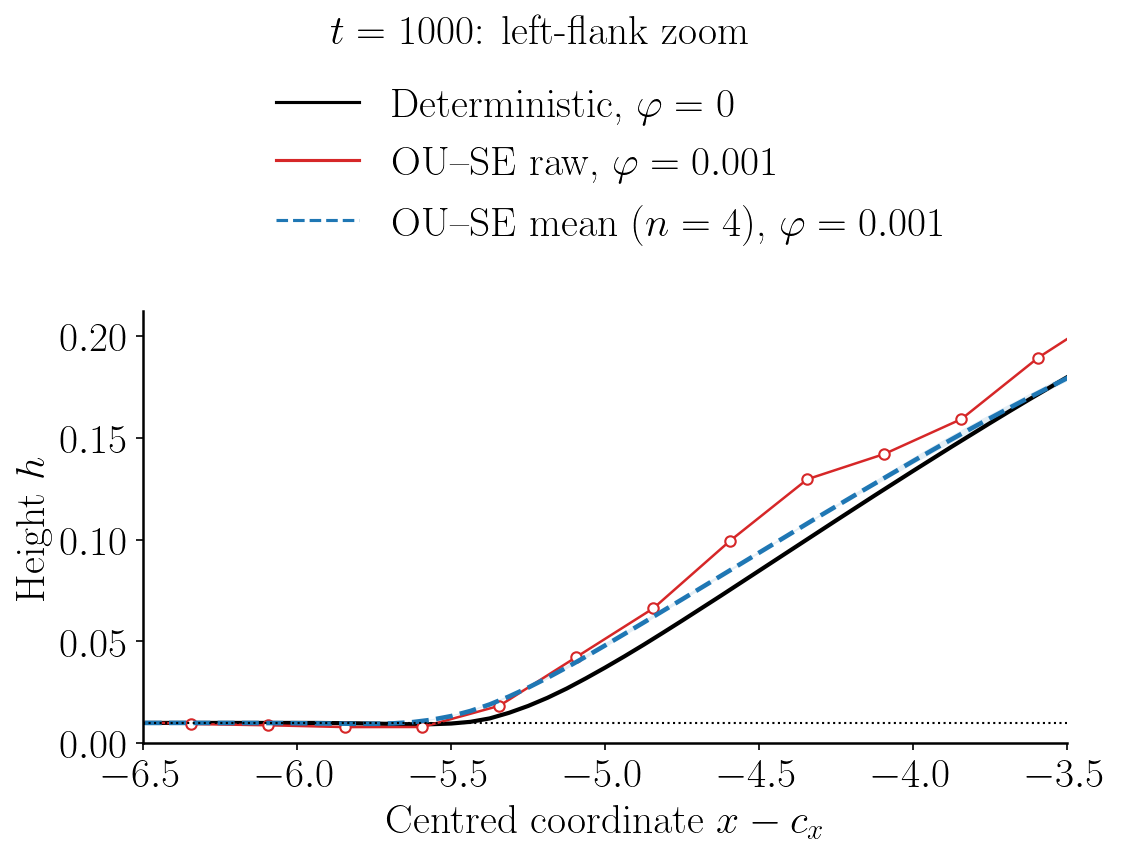

In [7]:
fig, ax = canvas()
fig.subplots_adjust(right=.94)
draw_profiles(ax, markers=True)
window_peaks = [h[(x >= SECTION_ZOOM[0]) & (x <= SECTION_ZOOM[1])].max()
                for x, h in [(raw_x, raw_h), (mean_x, mean_h+mean_sd), (det_x, det_h)]]
ax.set(xlim=SECTION_ZOOM, ylim=(0, 1.12*max(window_peaks)), xlabel=r'Centred coordinate $x-c_x$', ylabel=r'Height $h$')
fig.suptitle(rf'$t={SECTION_TIME}$: left-flank zoom', y=.98)
fig.legend(handles=profile_handles, loc='upper center', bbox_to_anchor=(.56, .94))
finish(fig, '03_ou_raw_mean_det_zoom')

## 6. 保留同位置触底诊断
此处切换到白噪声最小高度网格，三方法取**同一个物理y行**，均为原始单场截线。它不是前面的中心/环均对比。红色=OU、蓝色=白噪声、黑色=无涨落。有限数值下界上的单格事件不能直接称为物理破裂。

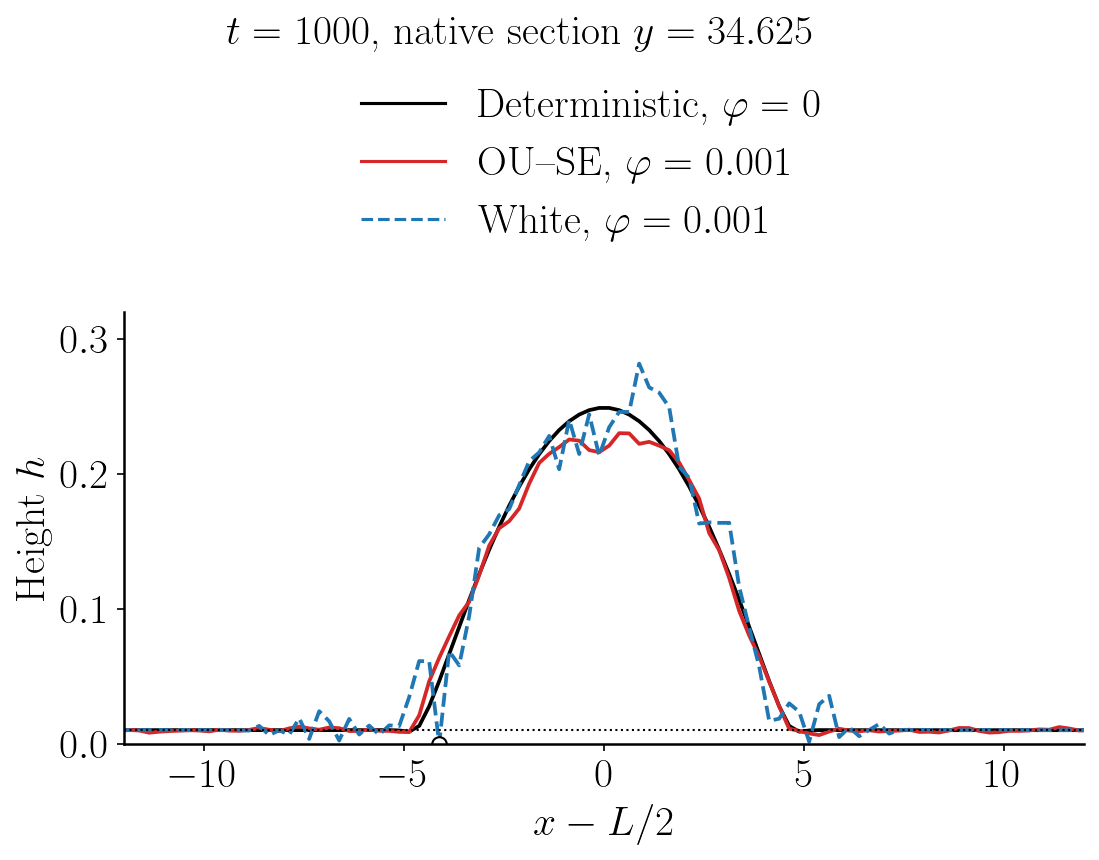

白噪声选中格: x=27.875, y=34.625, 严格触底=True


In [8]:
iy, ix = np.unravel_index(np.argmin(W), W.shape)
x_star, y_star = xy[ix], xy[iy]
strict = bool(W[iy, ix] <= meta['lower_bound'])
contact_handles = [
    Line2D([], [], color=BLACK, label=r'Deterministic, $\varphi=0$'),
    Line2D([], [], color=RED, label=rf'OU--SE, $\varphi={PHI:g}$'),
    Line2D([], [], color=BLUE, ls='--', label=rf'White, $\varphi={PHI:g}$'),
]
fig, ax = canvas()
for h, color, ls in [(H, BLACK, '-'), (U, RED, '-'), (W, BLUE, '--')]:
    ax.plot(xy-L/2, h[iy], color=color, ls=ls, lw=1.8)
ax.axhline(HP, color=BLACK, ls=':', lw=1)
ax.plot(x_star-L/2, W[iy, ix], 'o', color=BLACK, mfc='white', ms=7)
ax.set(xlim=SECTION_XLIM, ylim=(0, .32), xlabel=r'$x-L/2$', ylabel=r'Height $h$')
fig.suptitle(rf'$t={SECTION_TIME}$, native section $y={y_star:g}$', y=.98)
fig.legend(handles=contact_handles, loc='upper center', bbox_to_anchor=(.56, .94))
finish(fig, '04_contact_section_three_modes')
print(f'白噪声选中格: x={x_star:g}, y={y_star:g}, 严格触底={strict}')

### 同一原始截线的放大（纵轴log）

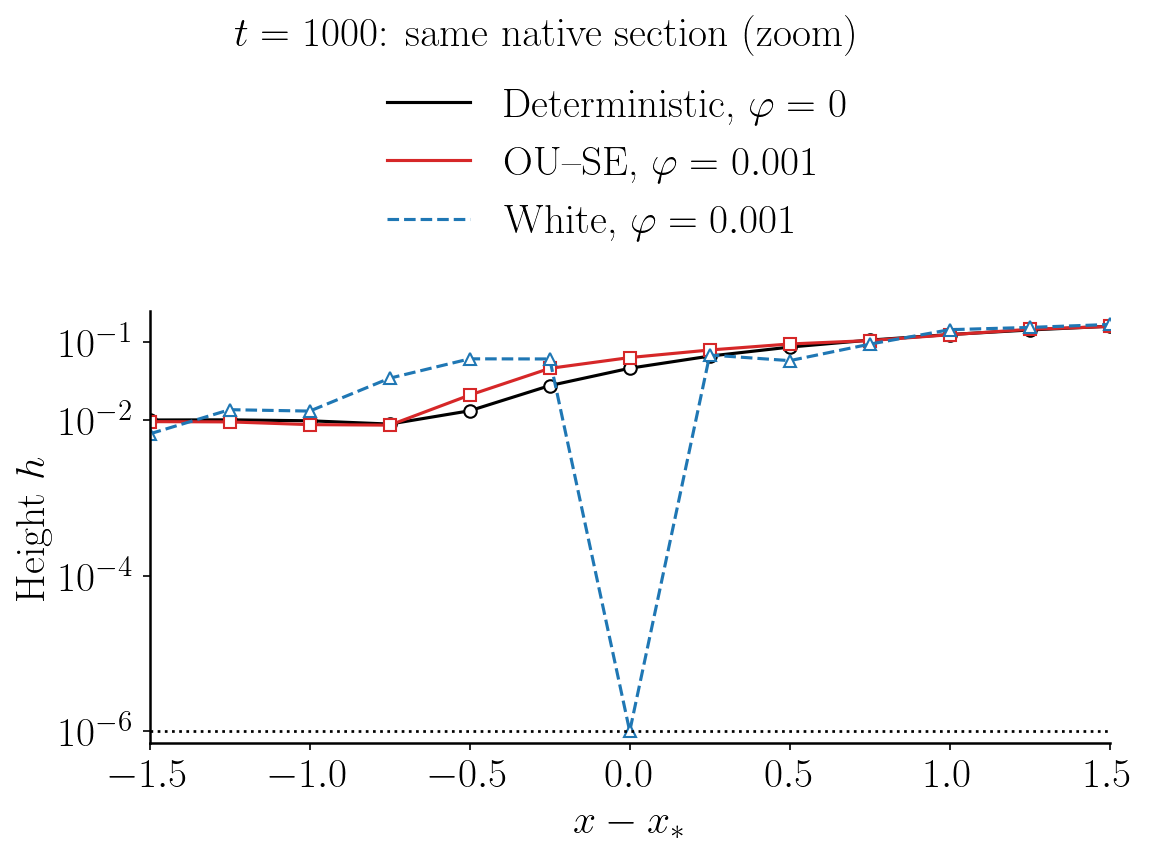

In [9]:
fig, ax = canvas()
m = abs(xy-x_star) <= CONTACT_HALF_WIDTH
for h, color, ls, marker in [(H, BLACK, '-', 'o'), (U, RED, '-', 's'), (W, BLUE, '--', '^')]:
    ax.plot(xy[m]-x_star, h[iy, m], color=color, ls=ls, marker=marker, mfc='white', ms=6, lw=1.5)
ax.axhline(meta['lower_bound'], color=BLACK, ls=':', lw=1.3)
ax.set(yscale='log', xlim=(-CONTACT_HALF_WIDTH, CONTACT_HALF_WIDTH), ylim=(7e-7, .25), xlabel=r'$x-x_*$', ylabel=r'Height $h$')
ax.set_yticks([1e-6, 1e-4, 1e-2, 1e-1])
fig.suptitle(rf'$t={SECTION_TIME}$: same native section (zoom)', y=.98)
fig.legend(handles=contact_handles, loc='upper center', bbox_to_anchor=(.56, .94))
finish(fig, '05_contact_section_zoom')

### 二维原网格放大
共同灰度色标，9×9原生网格不平滑。红格=严格$h\le10^{-6}$，蓝格=仅位于舍入容差$64\epsilon_{mach}h_p$内。选点相同，不把累计限制器次数当作面积。

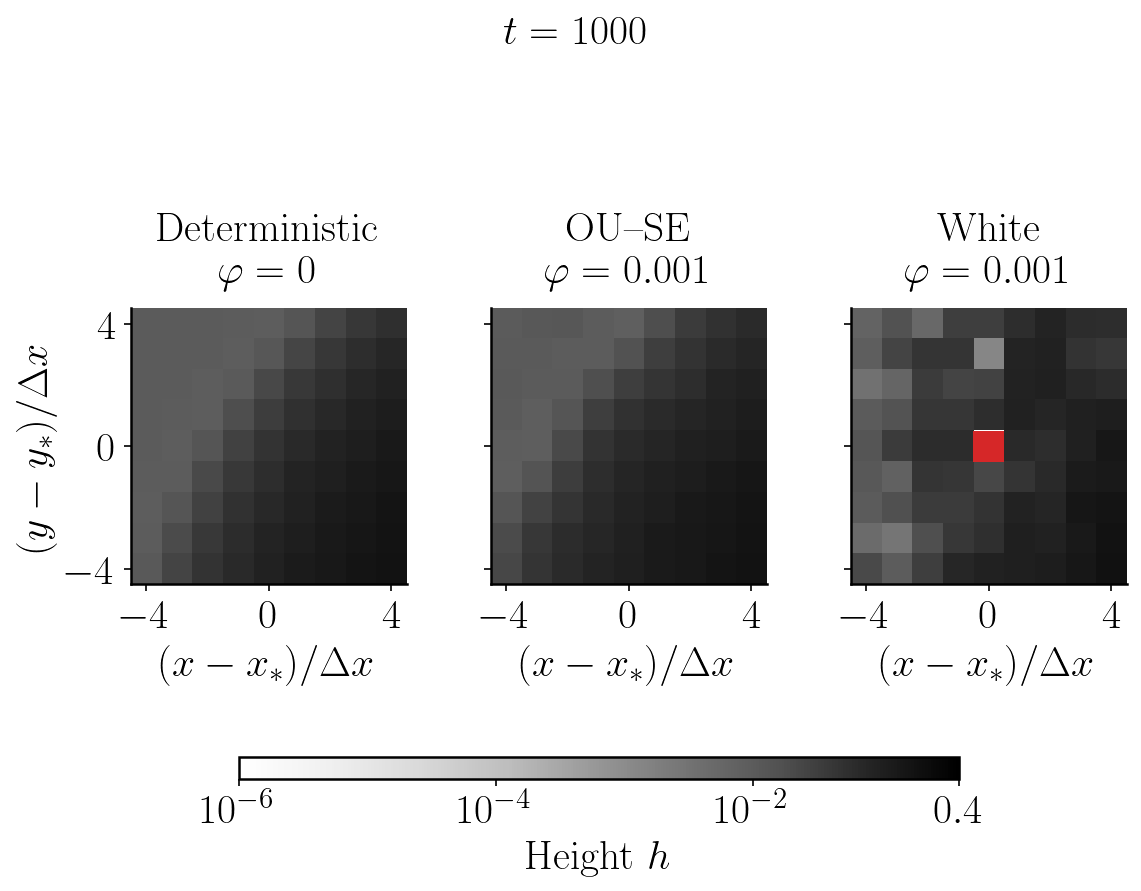

In [10]:
fig = plt.figure(figsize=(8, 6))
axes = [fig.add_axes([left, .29, .23, .42]) for left in [.13, .43, .73]]
titles = [('Deterministic', 0), ('OU--SE', PHI), ('White', PHI)]
for ax, h, (method, phi) in zip(axes, [H, U, W], titles):
    rows = np.arange(iy-4, iy+5) % len(h)
    cols = np.arange(ix-4, ix+5) % len(h)
    z = h[np.ix_(rows, cols)]
    image = ax.imshow(z, origin='lower', extent=(-4.5, 4.5, -4.5, 4.5), cmap='Greys', norm=LogNorm(1e-6, .4), interpolation='nearest')
    for j, k in np.argwhere(z <= 1e-6 + 64*np.finfo(float).eps*HP):
        ax.add_patch(Rectangle((k-4.5, j-4.5), 1, 1, facecolor=RED if z[j, k] <= 1e-6 else BLUE, edgecolor='none'))
    ax.set(xticks=[-4, 0, 4], yticks=[-4, 0, 4], xlabel=r'$(x-x_*)/\Delta x$')
    if ax is not axes[0]:
        ax.set_yticklabels([])
    ax.set_title(method+'\n'+rf'$\varphi={phi:g}$', pad=12)
axes[0].set_ylabel(r'$(y-y_*)/\Delta x$')
fig.suptitle(rf'$t={SECTION_TIME}$', y=.98)
bar = fig.colorbar(image, cax=fig.add_axes([.22, .13, .60, .025]), orientation='horizontal', ticks=[1e-6, 1e-4, 1e-2, .4])
bar.set_ticklabels([r'$10^{-6}$', r'$10^{-4}$', r'$10^{-2}$', r'$0.4$'])
bar.set_label(r'Height $h$'); bar.minorticks_off()
finish(fig, '06_contact_region_three_modes')

## 7. 导出与结论边界
每个图导出8×6英寸矢量PDF和600dpi PNG。无涨落旧版本/步长差异、白噪声掩膜与OU全场噪声差异均保留，因此不把本图作为纯算法稳定性或物理准确性排名。4seed并不证明长期统计或网格收敛。

In [11]:
pd.DataFrame(fit_rows).to_csv(OUTPUT_DIR / 'late_exponents.csv', index=False)
summary = {
    'native_time': SECTION_TIME, 'raw_OU_case': OU_RAW_CASE,
    'raw_OU_row_y': float(xy[raw_row]), 'raw_OU_core_cy': cy,
    'OU_mean_seeds': OU_CASES, 'noise_phi': PHI, 'deterministic_phi': 0,
    'contact_x': float(x_star), 'contact_y': float(y_star), 'strict_contact': strict,
    'contact_heights': {'Deterministic': float(H[iy, ix]), 'OU-SE': float(U[iy, ix]), 'White': float(W[iy, ix])},
    'radius_q': meta['radius_q'], 'fit_window': FIT_WINDOW,
    'deterministic_extrapolated': False, 'native_SHA_checks': len(native),
    'radius_rechecks': len(observations), 'fit_results': fit_rows,
}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
display(pd.DataFrame([summary['contact_heights']]))
print('完成：图像保存在', OUTPUT_DIR)

,Deterministic,OU-SE,White
0,0.046318,0.063575,1.000000e-06


完成：图像保存在 figures
